In [1]:
!pip install -q rasterio

In [2]:
%cd /content
!git clone https://github.com/Marco415/image-classification-project.git image-classification-project
%cd /content/image-classification-project
!git checkout p-cnn
!git log --oneline -3

/content
Cloning into 'image-classification-project'...
remote: Enumerating objects: 69, done.
remote: Counting objects: 100% (24/24), done.
remote: Compressing objects: 100% (17/17), done.
remote: Total 69 (delta 10), reused 12 (delta 7), pack-reused 45 (from 2)
Receiving objects: 100% (69/69), 168.82 MiB | 31.55 MiB/s, done.
Resolving deltas: 100% (15/15), done.
Updating files: 100% (22/22), done.
/content/image-classification-project
branch 'p-cnn' set up to track 'origin/p-cnn'.
Switched to a new branch 'p-cnn'
4ba864a (HEAD -> p-cnn, origin/p-cnn) Add Custom CNN model
c0e5440 (origin/main, origin/HEAD, main) Fix gitignore
b289764 Upload ResNet model


In [3]:
from huggingface_hub import hf_hub_download, list_repo_files

print(list_repo_files("Ehzoahis/EuroSAT", repo_type="dataset"))   # check the zip's filename

hf_hub_download(
    repo_id="Ehzoahis/EuroSAT",
    filename="EuroSAT.zip",          # change this if the list above shows a different name
    repo_type="dataset",
    local_dir="data/raw",
)

['.gitattributes', 'EuroSAT.py', 'EuroSAT.zip', 'README.md']


EuroSAT.zip: reconstructing file:   0%|          |  0.00B / 2.07GB            

EuroSAT.zip: downloading bytes:           |  0.00B            

'/content/image-classification-project/data/raw/EuroSAT.zip'

In [4]:
!unzip -q data/raw/EuroSAT.zip -d data/raw
!ls data/raw/EuroSAT

metadata.csv  test  train  val


In [5]:
import os
os.chdir("/content/image-classification-project/notebooks")
!pwd
!nvidia-smi

/content/image-classification-project/notebooks
Tue Nov  3 08:24:41 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   43C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |


In [6]:
# 1. imports
import sys, json, random, platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

import torch
import torch.nn as nn
from torch.utils.data import DataLoader

src_path = Path("src").resolve() if Path("src").exists() else (Path("..").resolve() / "src")
if str(src_path) not in sys.path:
    sys.path.insert(0, str(src_path))
print(f"Loading modules from: {src_path}")

from dataset_utils import EuroSATDataset, CLASS_NAMES, read_geotiff
from model_utils import create_custom_cnn
from training_utils import train_model
from evaluation_utils import predict, evaluate_predictions, get_confusion_matrix

Loading modules from: /content/image-classification-project/src


In [13]:
# 2. config, seed, device
CONFIG = dict(
    model="CustomCNN (4 conv blocks, from scratch, no pretrained weights)",
    input_size=64, batch_size=64, accumulation_steps=1,
    epochs=10, patience=11,
    optimizer="AdamW", lr=1e-3, weight_decay=1e-4,
    scheduler="CosineAnnealingLR(T_max=40)",
    loss="CrossEntropyLoss", class_weights=None,
    dropout=0.3, seed=42,
)

SEED = CONFIG["seed"]
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("scikit-learn:", sklearn.__version__, "| NumPy:", np.__version__)
print("Device:", device)
if device.type == "cuda":
    p = torch.cuda.get_device_properties(0)
    print("GPU:", p.name, "| Memory (GB):", round(p.total_memory / 1e9, 1))

Python: 3.13.16
PyTorch: 2.11.0+cu130
scikit-learn: 1.6.1 | NumPy: 2.4.6
Device: cuda
GPU: Tesla T4 | Memory (GB): 15.6


In [14]:
# 3. load the splits and fix the path
RAW_ROOT = (Path("..") / "data" / "raw" / "EuroSAT").resolve()

def fix_path(p):
    tail = p.replace("\\", "/").split("/EuroSAT/")[-1]
    return str(RAW_ROOT / tail)

train_df = pd.read_csv("../data/splits/train.csv")
validation_df = pd.read_csv("../data/splits/validation.csv")
test_df = pd.read_csv("../data/splits/test.csv")

for df in (train_df, validation_df, test_df):
    df["image_path"] = df["image_path"].apply(fix_path)

missing = [p for df in (train_df, validation_df, test_df)
           for p in df["image_path"] if not Path(p).exists()]
print("Missing files:", len(missing))
assert len(missing) == 0, missing[:5]

with open("../data/splits/metadata.json") as f:
    metadata = json.load(f)
MEAN, STD = metadata["band_mean"], metadata["band_std"]

print(len(train_df), len(validation_df), len(test_df))

Missing files: 0
16200 5400 5400


In [15]:
# 4. dataset and loaders
IMG = CONFIG["input_size"]; BS = CONFIG["batch_size"]

train_dataset = EuroSATDataset(train_df, mean=MEAN, std=STD, image_size=IMG, augment=True)
validation_dataset = EuroSATDataset(validation_df, mean=MEAN, std=STD, image_size=IMG, augment=False)
test_dataset = EuroSATDataset(test_df, mean=MEAN, std=STD, image_size=IMG, augment=False)

pin = torch.cuda.is_available()
train_loader = DataLoader(train_dataset, batch_size=BS, shuffle=True, num_workers=2, pin_memory=pin)
validation_loader = DataLoader(validation_dataset, batch_size=BS, shuffle=False, num_workers=2, pin_memory=pin)
test_loader = DataLoader(test_dataset, batch_size=BS, shuffle=False, num_workers=2, pin_memory=pin)

x, y = next(iter(train_loader))
print(x.shape, y.shape)   # expect [64, 13, 64, 64]

torch.Size([64, 13, 64, 64]) torch.Size([64])


In [16]:
# 5. model
model = create_custom_cnn(num_classes=10, input_channels=13).to(device)

n_params = sum(p.numel() for p in model.parameters())
print("Total parameters:", n_params)
print(model)

Total parameters: 1178666
CustomCNN(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(13, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU(inplace=True)
      (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats

In [17]:
# 6. loss, optimiser, scheduler
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=CONFIG["lr"], weight_decay=CONFIG["weight_decay"])
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=CONFIG["epochs"])

In [18]:
# 7. train the model
Path("../models").mkdir(exist_ok=True)
Path("../results").mkdir(exist_ok=True)
Path("../figures").mkdir(exist_ok=True)

model, history = train_model(
    model=model,
    train_loader=train_loader,
    validation_loader=validation_loader,
    criterion=criterion,
    optimizer=optimizer,
    scheduler=scheduler,
    device=device,
    epochs=CONFIG["epochs"],
    patience=CONFIG["patience"],
    save_path="../models/custom_cnn_best.pth",
    accumulation_steps=CONFIG["accumulation_steps"],
)

with open("../results/custom_cnn_history.json", "w") as f:
    json.dump({"config": CONFIG, "history": history}, f, indent=2, default=float)

Epoch 01/10 | Train Loss: 0.6578 | Val Loss: 0.4790 | Train Acc: 0.7845 | Val Acc: 0.8426 | Val Macro F1: 0.8355 | 32.5s
Epoch 02/10 | Train Loss: 0.3667 | Val Loss: 0.3232 | Train Acc: 0.8831 | Val Acc: 0.8952 | Val Macro F1: 0.8927 | 32.6s
Epoch 03/10 | Train Loss: 0.2959 | Val Loss: 0.2086 | Train Acc: 0.9034 | Val Acc: 0.9315 | Val Macro F1: 0.9297 | 32.9s
Epoch 04/10 | Train Loss: 0.2252 | Val Loss: 0.1926 | Train Acc: 0.9276 | Val Acc: 0.9372 | Val Macro F1: 0.9352 | 32.9s
Epoch 05/10 | Train Loss: 0.2070 | Val Loss: 0.1579 | Train Acc: 0.9360 | Val Acc: 0.9474 | Val Macro F1: 0.9450 | 33.5s
Epoch 06/10 | Train Loss: 0.1666 | Val Loss: 0.1525 | Train Acc: 0.9477 | Val Acc: 0.9515 | Val Macro F1: 0.9496 | 33.6s
Epoch 07/10 | Train Loss: 0.1378 | Val Loss: 0.1719 | Train Acc: 0.9551 | Val Acc: 0.9443 | Val Macro F1: 0.9426 | 33.4s
Epoch 08/10 | Train Loss: 0.1198 | Val Loss: 0.0990 | Train Acc: 0.9605 | Val Acc: 0.9685 | Val Macro F1: 0.9676 | 33.6s
Epoch 09/10 | Train Loss: 0.1013

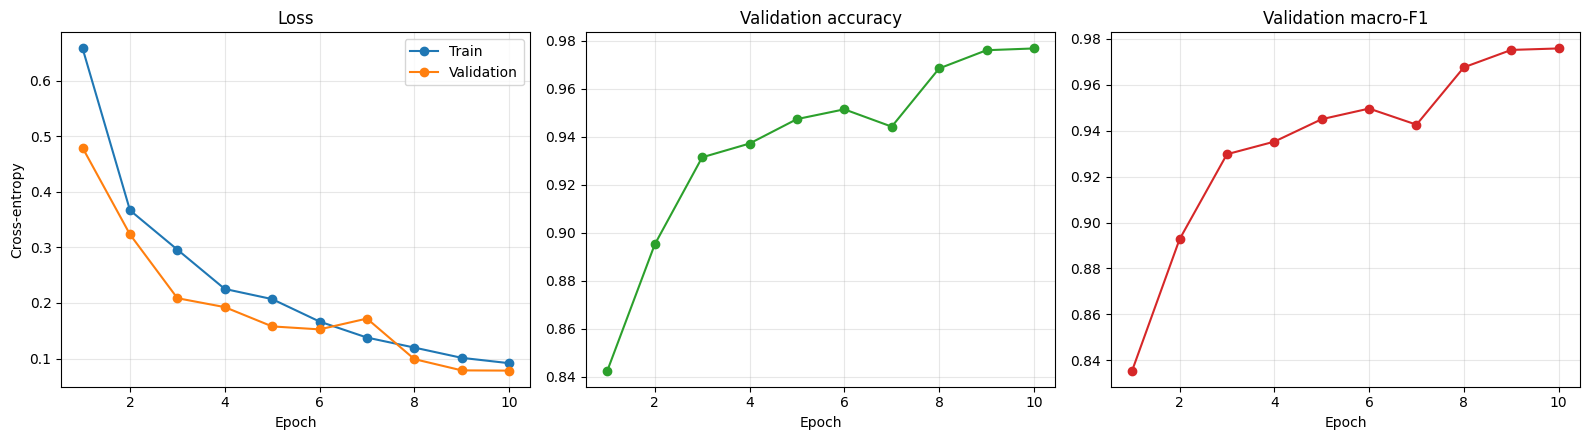

In [19]:
# 8. learning curves
ep = range(1, len(history["train_loss"]) + 1)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))

ax[0].plot(ep, history["train_loss"], marker="o", label="Train")
ax[0].plot(ep, history["validation_loss"], marker="o", label="Validation")
ax[0].set(title="Loss", xlabel="Epoch", ylabel="Cross-entropy"); ax[0].legend()

ax[1].plot(ep, history["validation_accuracy"], marker="o", color="tab:green")
ax[1].set(title="Validation accuracy", xlabel="Epoch")

ax[2].plot(ep, history["validation_macro_f1"], marker="o", color="tab:red")
ax[2].set(title="Validation macro-F1", xlabel="Epoch")

for a in ax: a.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("../figures/custom_cnn_learning_curves.png", dpi=300)
plt.show()

In [20]:
# 9. test set evaluation
ckpt = torch.load("../models/custom_cnn_best.pth", map_location=device, weights_only=True)
model.load_state_dict(ckpt["model_state_dict"])
print("Best epoch:", ckpt["epoch"], "| best val macro-F1:", round(ckpt["best_validation_macro_f1"], 4))

targets, preds, inf_time = predict(model, test_loader, device)
results, report = evaluate_predictions(targets, preds, CLASS_NAMES)

print({k: round(v, 4) for k, v in results.items()})
report_df = pd.DataFrame(report).T.round(4)
display(report_df)

Best epoch: 10 | best val macro-F1: 0.9758
{'accuracy': 0.9757, 'macro_precision': 0.9751, 'macro_recall': 0.9744, 'macro_f1': 0.9746, 'weighted_f1': 0.9757, 'balanced_accuracy': np.float64(0.9744)}


,precision,recall,f1-score,support
Annual Crop,0.9717,0.9799,0.9758,596.0000
Forest,0.9886,0.9984,0.9935,608.0000
Herbaceous Vegetation,0.9586,0.9703,0.9644,573.0000
Highway,0.9545,0.9718,0.9630,496.0000
Industrial Buildings,0.9938,0.9581,0.9756,501.0000
Pasture,0.9545,0.9545,0.9545,396.0000
Permanent Crop,0.9732,0.9442,0.9585,538.0000
Residential Buildings,0.9752,0.9928,0.9839,554.0000
River,0.9942,0.9735,0.9838,529.0000
SeaLake,0.9870,1.0000,0.9935,609.0000


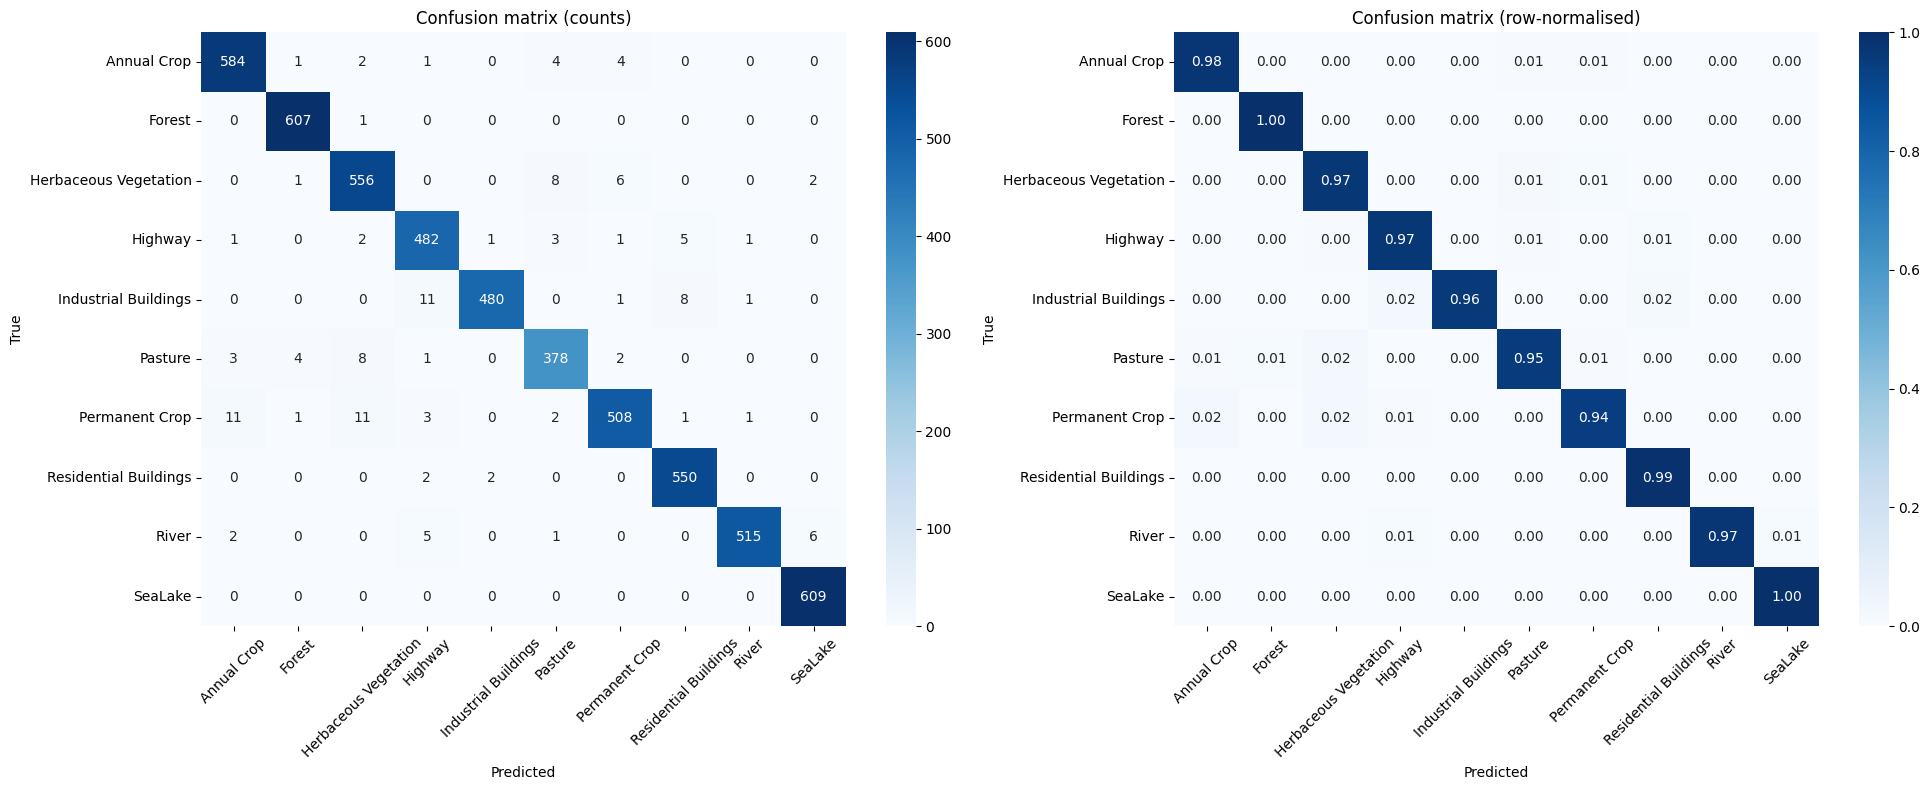

In [21]:
# 10. confusion matrix
cm = get_confusion_matrix(targets, preds)
cm_norm = cm / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(1, 2, figsize=(20, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax[0])
ax[0].set(title="Confusion matrix (counts)", xlabel="Predicted", ylabel="True")
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax[1])
ax[1].set(title="Confusion matrix (row-normalised)", xlabel="Predicted", ylabel="True")
for a in ax: a.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.savefig("../figures/custom_cnn_confusion_matrix.png", dpi=300)
plt.show()

In [22]:
# 11. class pairs
off = cm.copy(); np.fill_diagonal(off, 0)
pairs = sorted(
    [(CLASS_NAMES[i], CLASS_NAMES[j], int(off[i, j])) for i in range(10) for j in range(10) if off[i, j] > 0],
    key=lambda t: -t[2],
)
for true_c, pred_c, n in pairs[:10]:
    print(f"{true_c:>22} -> {pred_c:<22} {n}")

  Industrial Buildings -> Highway                11
        Permanent Crop -> Annual Crop            11
        Permanent Crop -> Herbaceous Vegetation  11
 Herbaceous Vegetation -> Pasture                8
  Industrial Buildings -> Residential Buildings  8
               Pasture -> Herbaceous Vegetation  8
 Herbaceous Vegetation -> Permanent Crop         6
                 River -> SeaLake                6
               Highway -> Residential Buildings  5
                 River -> Highway                5


Errors: 131 of 5400


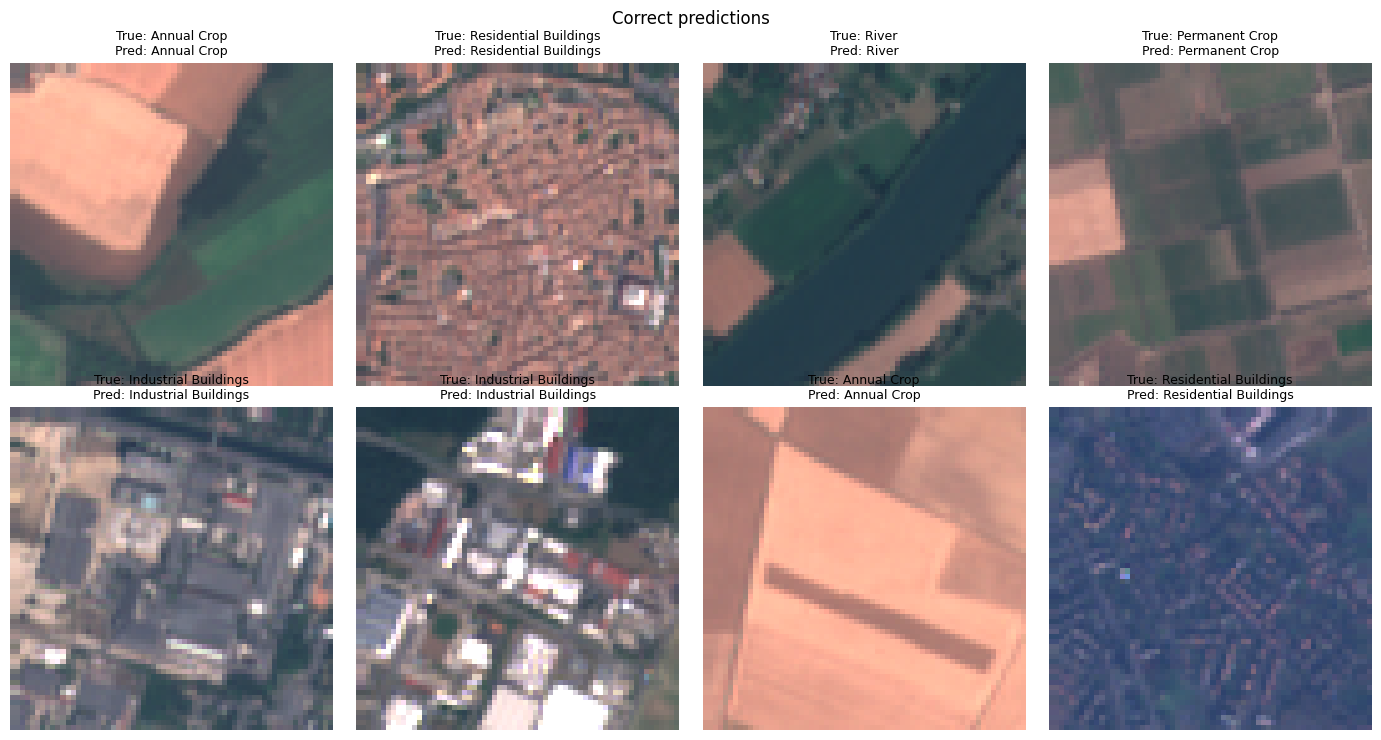

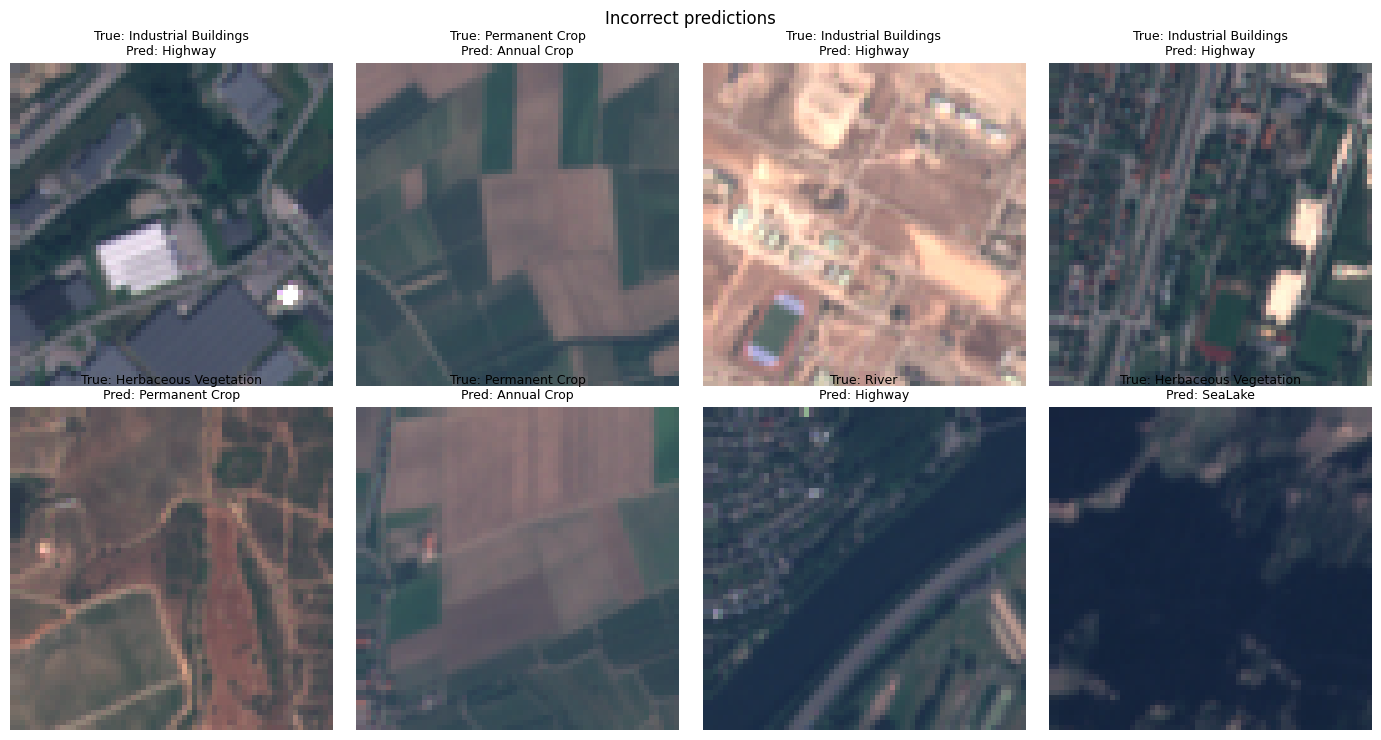

In [23]:
# 12. correct and incorrect examples
def to_rgb(path):
    img = read_geotiff(path).numpy()
    return np.clip(img[[3, 2, 1]].transpose(1, 2, 0) / 3000.0, 0, 1)

def show(indices, title, fname):
    fig, axes = plt.subplots(2, 4, figsize=(14, 7.5))
    for a, i in zip(axes.ravel(), indices):
        a.imshow(to_rgb(test_df.iloc[i]["image_path"]))
        a.set_title(f"True: {CLASS_NAMES[targets[i]]}\nPred: {CLASS_NAMES[preds[i]]}", fontsize=9)
        a.axis("off")
    fig.suptitle(title); plt.tight_layout()
    plt.savefig(fname, dpi=200); plt.show()

rng = np.random.default_rng(42)
correct = np.where(targets == preds)[0]
wrong = np.where(targets != preds)[0]
print("Errors:", len(wrong), "of", len(targets))

show(rng.choice(correct, 8, replace=False), "Correct predictions", "../figures/custom_cnn_correct_examples.png")
show(rng.choice(wrong, min(8, len(wrong)), replace=False), "Incorrect predictions", "../figures/custom_cnn_incorrect_examples.png")

In [24]:
# 13. extras and saving results
size_mb = Path("../models/custom_cnn_best.pth").stat().st_size / 1e6
ms_per_image = inf_time / len(test_df) * 1000
print(f"Parameters: {n_params:,} | checkpoint: {size_mb:.1f} MB | ~{ms_per_image:.2f} ms/image (includes data loading)")

with open("../results/custom_cnn_test_metrics.json", "w") as f:
    json.dump({"config": CONFIG, "test_metrics": results, "parameters": n_params,
               "checkpoint_mb": size_mb, "ms_per_image": ms_per_image,
               "best_epoch": ckpt["epoch"]}, f, indent=2, default=float)

report_df.to_csv("../results/custom_cnn_classification_report.csv")
pd.DataFrame({"row": np.arange(len(targets)), "true": targets, "pred": preds}).to_csv(
    "../results/custom_cnn_test_predictions.csv", index=False)

Parameters: 1,178,666 | checkpoint: 4.7 MB | ~1.41 ms/image (includes data loading)
